# Stage 2 | Evaluate fixed ACT policies with WorldGym

**Stage 1 produced policies that act. Stage 2 asks whether a world model can evaluate those policies.**

The central distinction is simple: **ACT executes, but its weights no longer learn**. Allow roughly 15–20 minutes. Follow the overview from panel 1 to panel 5. Understanding who produces future observations makes the later scores and rankings easier to interpret.

![Stage 2 overview: frozen ACT policies run independently in model and MuJoCo environments; native and hybrid routes, evaluation metrics, strong baselines and the transition to RL are separated.](media/figures/02_results.png)

[Open the full-size overview](media/figures/02_results.png). The ordering drawn in the image is conceptual; the plots below use the archived policy-level data.

## 1 What are we evaluating?

**Look at the seven locked policy cards in the upper-left panel.** Stage 1 and subsequent ACT training produced checkpoints with different capabilities. Some often fail; others almost always succeed. We want an evaluator that can tell them apart.

The direct approach runs every ACT in MuJoCo on the same initial states and counts official successes. This is the project's physical-simulation reference. World-model evaluation asks: **starting from an initial observation, can predicted futures also estimate how well these policies will perform?** We still need MuJoCo to test whether those estimates are credible. This experiment does not establish that model-based evaluation is cheaper.

| Shared between the two paths | What differs |
|---|---|
| Same ACT checkpoint, initial-state seed and task | Physical dynamics produce future observations in MuJoCo |
| ACT chooses actions from its current observation | Learned models produce future observations on the model path |
| ACT weights remain fixed during evaluation | Different feedback can cause subsequent ACT actions to diverge |

Thus, “same policy, same initial state” does not imply an identical action sequence throughout. If the model predicts the tube in the wrong place, ACT responds to that incorrect observation. This is part of the closed-loop evaluation problem. The model path is not fed the real future images and actions as an answer key.

> **Keep the roles clear:** ACT is being evaluated. WorldGym and its supporting components form an evaluation environment. The evaluator may itself require training or calibration, but the evaluated ACT is not updated during this stage.

## 2 How is a policy scored?

**Follow one trip around the upper-right feedback loop.** MuJoCo reset supplies the initial camera images and robot state. ACT produces actions; the model predicts observations after those actions; ACT reads those predicted observations and acts again. Future real images are not used as inputs to this model loop.

Two routes were explored, and their results must remain distinct:

| Route | Where future images come from | How to interpret the result |
|---|---|---|
| **Native WorldGym** | Action-conditioned video/latent generation decoded through a VAE; a separate predictor supplies joint observations | Tests native generated futures; contact, grasping and lifting remain problematic in this task |
| **Hybrid evaluator** | WorldGym features support learned state/finger dynamics, followed by CAD camera rendering | The stronger policy-ranking results belong to this combination, not directly generated native RGB |

CAD rendering draws a camera view from predicted geometry. Rendering a state does not guarantee correct contact dynamics or object motion. A hybrid evaluator can therefore rank policies usefully while still making trajectory-level physical errors.

A generated trajectory also needs a score. The frozen main evaluator uses visual scoring followed by a single global calibrator fitted on **development data** to map scores into success probabilities. Calibration makes scores more consistent with observed success frequencies. It does not change ACT or guarantee correct probabilities for every new scene.

Each policy receives one predicted probability for each of 20 initial states. Their mean becomes its predicted success rate, and policies are ranked by that mean. **Averaging 20 probabilities differs from counting how many exceed 0.5.** The policy ranking here uses the former.

**A concrete recorded example:** the repaired 10-demo ACT `ea4310c7` succeeded in 11 of this experiment's 20 MuJoCo scenes: 55%. The hybrid evaluator's mean predicted probability was about 58.2%. These are close at the policy level. That does not mean every individual success or failure was correctly identified.

## 3 What actually happened

**Now read the three metrics in the overview.** The main test used seven fixed ACT checkpoints and 20 new initial states: 140 policy–scene combinations. Results were summarized after the complete matrix finished.

| Metric | Recorded result | What it asks |
|---|---:|---|
| Pairwise policy ordering | 18/20, 90% | For two policies with different measured capability, is the better one ranked higher? |
| Episode success/failure classification | 125/140, 89.3% | Is one policy–scene outcome correctly classified? |
| Spearman rank correlation | 0.919 | How closely does the overall policy order match MuJoCo? |

Why are there 20 policy pairs? Seven policies give 21 pairs, but one pair has identical measured success rates. That pair has no strictly better policy, leaving 20 non-tied pairs. **89.3% is evaluator classification accuracy, not a robot's pickup success rate.**

The next plot places the measured MuJoCo rate and estimated hybrid probability beside each policy. Short bars indicate weak policies. Two similar bars indicate a close estimate. The ordering across policies addresses ranking.

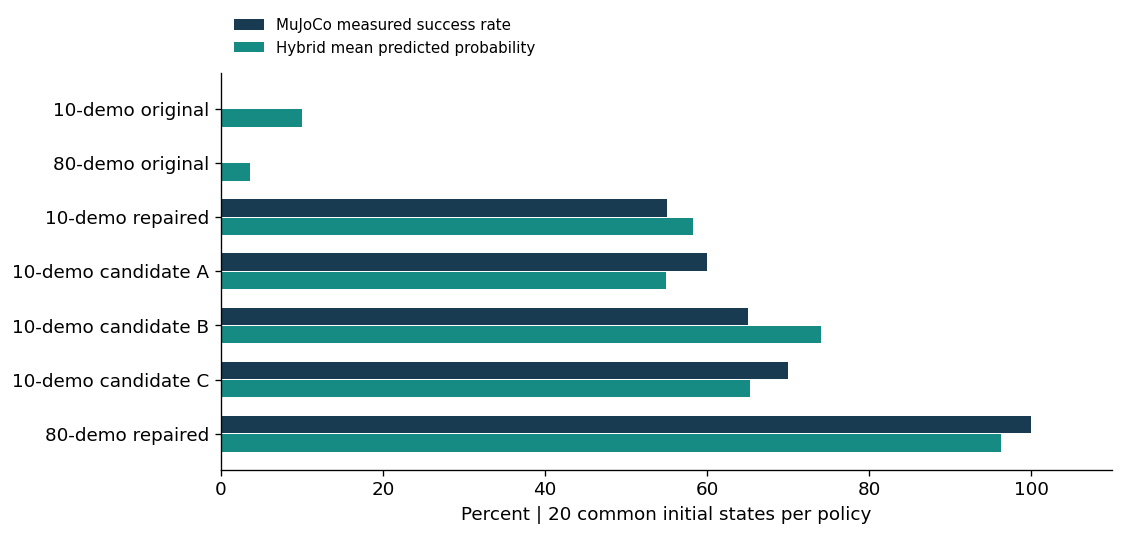

Frozen ACT policy,MuJoCo successes,Hybrid predicted probability
10-demo original,0/20,10.0%
80-demo original,0/20,3.6%
10-demo repaired,11/20,58.2%
10-demo candidate A,12/20,54.9%
10-demo candidate B,13/20,74.0%
10-demo candidate C,14/20,65.2%
80-demo repaired,20/20,96.2%


In [1]:
from briefing_utils import *
verify_assets()
check_stage_evidence()
phase2_results()

Here the repaired 80-demo ACT scores 20/20, and the 10-demo ACT 11/20. This does not contradict 50/50 and 31/50 in the first notebook: **the checkpoints are the same, but the test initial states differ**. Choosing each policy's most favorable result from different test batches would not be a valid comparison.

Optional arithmetic: classify a saved probability of at least 0.5 as success and compare it with the independent MuJoCo label.

In [2]:
cases = pd.read_csv(ROOT / 'evidence/phase2_outcomes.csv')
predicted_success = cases.worldgym_probability >= 0.5
correct = int((predicted_success == cases.success.astype(bool)).sum())
print(f'Correct episode judgments: {correct}/{len(cases)} = {correct / len(cases):.1%}')

Correct episode judgments: 125/140 = 89.3%


A separately reserved confirmation set of 20 new initial states gave 19/19 correctly ordered non-tied pairs and 94.3% episode accuracy for the same frozen hybrid method. These were not scores after another calibration round, and they do not replace the main result above. Seven policies are still a small comparison set, especially for closely matched policies.

## 4 What the results support

**Start with the lower-left panel: what is the comparator?** If a strong method without WorldGym performs similarly, the full result cannot be attributed to WorldGym.

The matched **no-WorldGym dynamics + visual** baseline also achieved 90% pairwise ordering accuracy and about 87.9% episode accuracy on the main test. The WorldGym hybrid had better probability errors on some metrics, but a stable general advantage was not established. The control matched state-head capacity and supervision; it did not match every pretrained parameter or the total computation of the systems.

Now consider a **later, separate policy-selection experiment**. It trained more SFT candidates, selected among them using different evaluators, then tested the selected policies on 100 common new MuJoCo scenes.

| Method or reference | Successes / 100 |
|---|---:|
| Original ACT | 78 |
| Policy selected by the WorldGym evaluator | 94 |
| Policy selected by the strong no-WorldGym visual selector | 93 |
| Fixed FT40 SFT candidate | 94 |

**A selected policy outperforming old ACT does not mean WorldGym caused the entire improvement.** The 94−78 difference is 16 percentage points, showing a better candidate than that starting policy. But fixed FT40 also scores 94, and the strong selector already reaches 93. WorldGym's difference from that selector is only +1 point, with a scene-paired 95% interval of approximately [−5,+8]. A clear selection benefit is therefore unestablished. This is a different matrix from the seven-policy ranking test.

In [3]:
selection = outcomes('gain')
table([[name, int(selection[key].sum())] for name, key in [
    ('Original ACT', 'original_ACT'),
    ('WorldGym-selected / fixed FT40', 'FT40_s5101_step10000'),
    ('Strong no-WorldGym selector', 'FT20_s5102_step5000')]],
    ['Separate selection experiment', 'Successes / 100'])

Separate selection experiment,Successes / 100
Original ACT,78
WorldGym-selected / fixed FT40,94
Strong no-WorldGym selector,93


We also need to ask why an evaluator is wrong. Its future image/state prediction may be wrong, or its scorer may misread a reasonable image. A total score cannot separate these mechanisms. Native generation has not established reliable grasp-physics prediction here; useful hybrid rankings do not establish a generally accurate physical simulator.

## 5 The bridge to reinforcement learning

**The lower-right panel marks the boundary between Stages 2 and 3.** So far, policies run with fixed weights and we estimate their performance. Using trajectory scores as rewards to change policy parameters is the next step: reinforcement learning.

This raises an additional concern. An evaluator that separates existing good and bad policies can still be exploited by optimization. A policy might make generated images look like successful pickup without actually lifting a tube in MuJoCo. Stage 3 must therefore check future generation, visual reward, policy updates and independent task evaluation separately.

**A precise research summary:** “I compared fixed ACT policies in model and MuJoCo environments, obtained useful task-specific hybrid evaluation results, and used native generation and strong baselines to identify limitations in physical prediction and contribution attribution.”

**Reproduction scope:** the [evaluation entry](Scripts/evaluate.py) supports MuJoCo and native WorldGym. Full historical hybrid-evaluator training and campaign orchestration are outside the compact `Scripts/` release. This notebook verifies saved rankings and classifications on CPU; that arithmetic is not new model inference.

Before continuing, explain why ACT is frozen, why 89.3% is not pickup success, how native and hybrid future images differ, and why a no-WorldGym comparator is necessary.

[Back to Stage 1](01_act_imitation_learning.ipynb) · [Continue to Stage 3: RL inside WorldGym](03_worldgymnast_reinforcement_learning.ipynb)

<details><summary>Evidence sources</summary>

[Stage 2 summary and source fingerprints](evidence/phase2_summary.json); [all 140 main-test probabilities and labels](evidence/phase2_outcomes.csv); [later policy-selection results](evidence/gain_results.json). Confirmation numbers quote an archived summary, without fresh inference. Predicted probability and physical task success remain distinct throughout.

</details>